# Krones — Failure Mode Analysis

Goal: understand exactly *where and why* the trained classifier fails on val.
Decisions made downstream of this notebook depend on its answers, so we are
trying to be honest with the data rather than rationalize what we already think.

## Inputs needed
- `runs/baseline_resnet50/eval_test.csv` (or eval_val.csv) — per-image predictions
- `audit_output/splits.csv` — per-image labels and dominant defect
- `audit_output/crops_meta.csv` — crop bboxes
- `train_annotations.json` — annotation polygons (for area calculation)
- `audit_output/crops/` — the cropped images themselves

## What we look for, in order
1. **Confusion matrix recap**
2. **Conditional-class area distribution** — where do the errors sit relative to the threshold?
3. **Misclassified images grid** — visual inspection of failures
4. **Confidence distribution of errors** — does the model err *confidently*?
5. **Per-class error decomposition** — which classes account for most errors?
6. **Final verdict cell** — what the data says we should do next.

In [1]:
# Setup
import os
import json
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

ROOT = Path("/home/dll0202/baksh/dataset/1st-krones-vision-ai-challenge")
AUDIT_DIR = ROOT / "audit_output"
CROPS_DIR = AUDIT_DIR / "crops"
ANN_PATH = ROOT / "train_annotations.json"
EVAL_CSV = Path(
    "/home/dll0202/baksh/krones_2.0/Codebase/Codebase_2.0/runs/resnet50_640/eval_test.csv"
)
SPLITS_CSV = AUDIT_DIR / "splits.csv"
META_CSV = AUDIT_DIR / "crops_meta.csv"

# Conditional thresholds — same as label_audit.py
CONDITIONAL = {
    "Scuffing": 75000,
    "Air bubble": 500,
    "Contamination light": 180,
    "Chip": 200,
    "Scuffing heavy": 1200,
    "Glass imperfection": 100,
}

for p in (EVAL_CSV, SPLITS_CSV, META_CSV, ANN_PATH):
    print(f"{p.name}  exists: {p.exists()}")

eval_test.csv  exists: True
splits.csv  exists: True
crops_meta.csv  exists: True
train_annotations.json  exists: True


In [2]:
# Load everything
evals = pd.read_csv(EVAL_CSV)
splits = pd.read_csv(SPLITS_CSV)
meta = pd.read_csv(META_CSV)
with open(ANN_PATH) as f:
    ann = json.load(f)
cats = {c["id"]: c["name"] for c in ann["categories"]}
name2id = {v: k for k, v in cats.items()}

# Build per-image annotation area lookup (for conditional analysis)
img_class_area = defaultdict(lambda: Counter())
for a in ann["annotations"]:
    cn = cats[a["category_id"]]
    if cn in {"Roi"}:
        continue
    img_class_area[a["image_id"]][cn] += float(a.get("area", 0.0))

# eval.py wrote class names already, but cls_idx column maps to splits['dominant'] order
# Easiest path: re-merge by file order. eval.py writes rows in the order of the val split.
# So evals + splits[split=='val'/'test'] will line up if we filter correctly.
split_name = "test" if "eval_test" in EVAL_CSV.name else "val"
split_rows = splits[splits["split"] == split_name].reset_index(drop=True)
if len(split_rows) != len(evals):
    print(f"WARNING length mismatch: split_rows={len(split_rows)} evals={len(evals)}")
    print("Will trust the class column already in evals.")
    df = evals.copy()
    df["file_name"] = split_rows["file_name"].values[: len(df)]  # best effort
    df["image_id"] = split_rows["image_id"].values[: len(df)]
else:
    df = evals.copy()
    df["file_name"] = split_rows["file_name"].values
    df["image_id"] = split_rows["image_id"].values
    df["borderline"] = (
        split_rows["borderline"].values if "borderline" in split_rows else 0
    )

# add cond_area for each image (total annotation area of the dominant defect)
df["cond_area"] = df.apply(
    lambda r: img_class_area.get(r["image_id"], {}).get(r["class"], 0.0), axis=1
)
df["threshold_for_class"] = df["class"].map(CONDITIONAL).fillna(np.nan)
df["error"] = (df["label"] != df["predbest"]).astype(int)
df["err_type"] = np.where(
    df["error"] == 0,
    "correct",
    np.where(
        (df["label"] == 1) & (df["predbest"] == 0), "FN_missed_defect", "FP_false_alarm"
    ),
)

n_total = len(df)
n_err = df["error"].sum()
print(f"rows: {n_total}   errors: {n_err}   error rate: {n_err / n_total * 100:.2f}%")
print(df["err_type"].value_counts().to_string())

rows: 3533   errors: 148   error rate: 4.19%
err_type
correct             3385
FP_false_alarm        84
FN_missed_defect      64


## 1. Confusion matrix and global summary

In [3]:
from sklearn.metrics import confusion_matrix, f1_score

cm = confusion_matrix(df["label"], df["predbest"], labels=[0, 1])
f1 = f1_score(df["label"], df["predbest"])
print(f"F1: {f1:.4f}\n")
print("                pred Good  pred Faulty")
print(f"  true Good      {cm[0, 0]:8d}   {cm[0, 1]:8d}")
print(f"  true Faulty    {cm[1, 0]:8d}   {cm[1, 1]:8d}")
print()
print(f"False Negatives (missed defects) : {cm[1, 0]}  <- DANGEROUS in production")
print(
    f"False Positives (false alarms)   : {cm[0, 1]}  <- COSTLY (rejecting reusable bottles)"
)
ratio_fn = cm[1, 0] / max(1, cm[1, 0] + cm[1, 1])
ratio_fp = cm[0, 1] / max(1, cm[0, 0] + cm[0, 1])
print(f"\nFN rate: {ratio_fn * 100:.2f}%   FP rate: {ratio_fp * 100:.2f}%")

F1: 0.9643

                pred Good  pred Faulty
  true Good          1389         84
  true Faulty          64       1996

False Negatives (missed defects) : 64  <- DANGEROUS in production
False Positives (false alarms)   : 84  <- COSTLY (rejecting reusable bottles)

FN rate: 3.11%   FP rate: 5.70%


## 2. Conditional classes — where do errors sit on the area axis?

**The key plot.** For each conditional class:
- X-axis: total annotation area on that image (in pixels)
- Vertical line: the area threshold (Faulty if area > threshold)
- Color: green = correct, red = misclassified

If errors cluster *near the threshold*, the model is making the right kind of judgment but at the wrong cutoff — a fixable problem. If errors are *spread evenly*, the model isn't measuring area at all and segmentation is the right pivot.

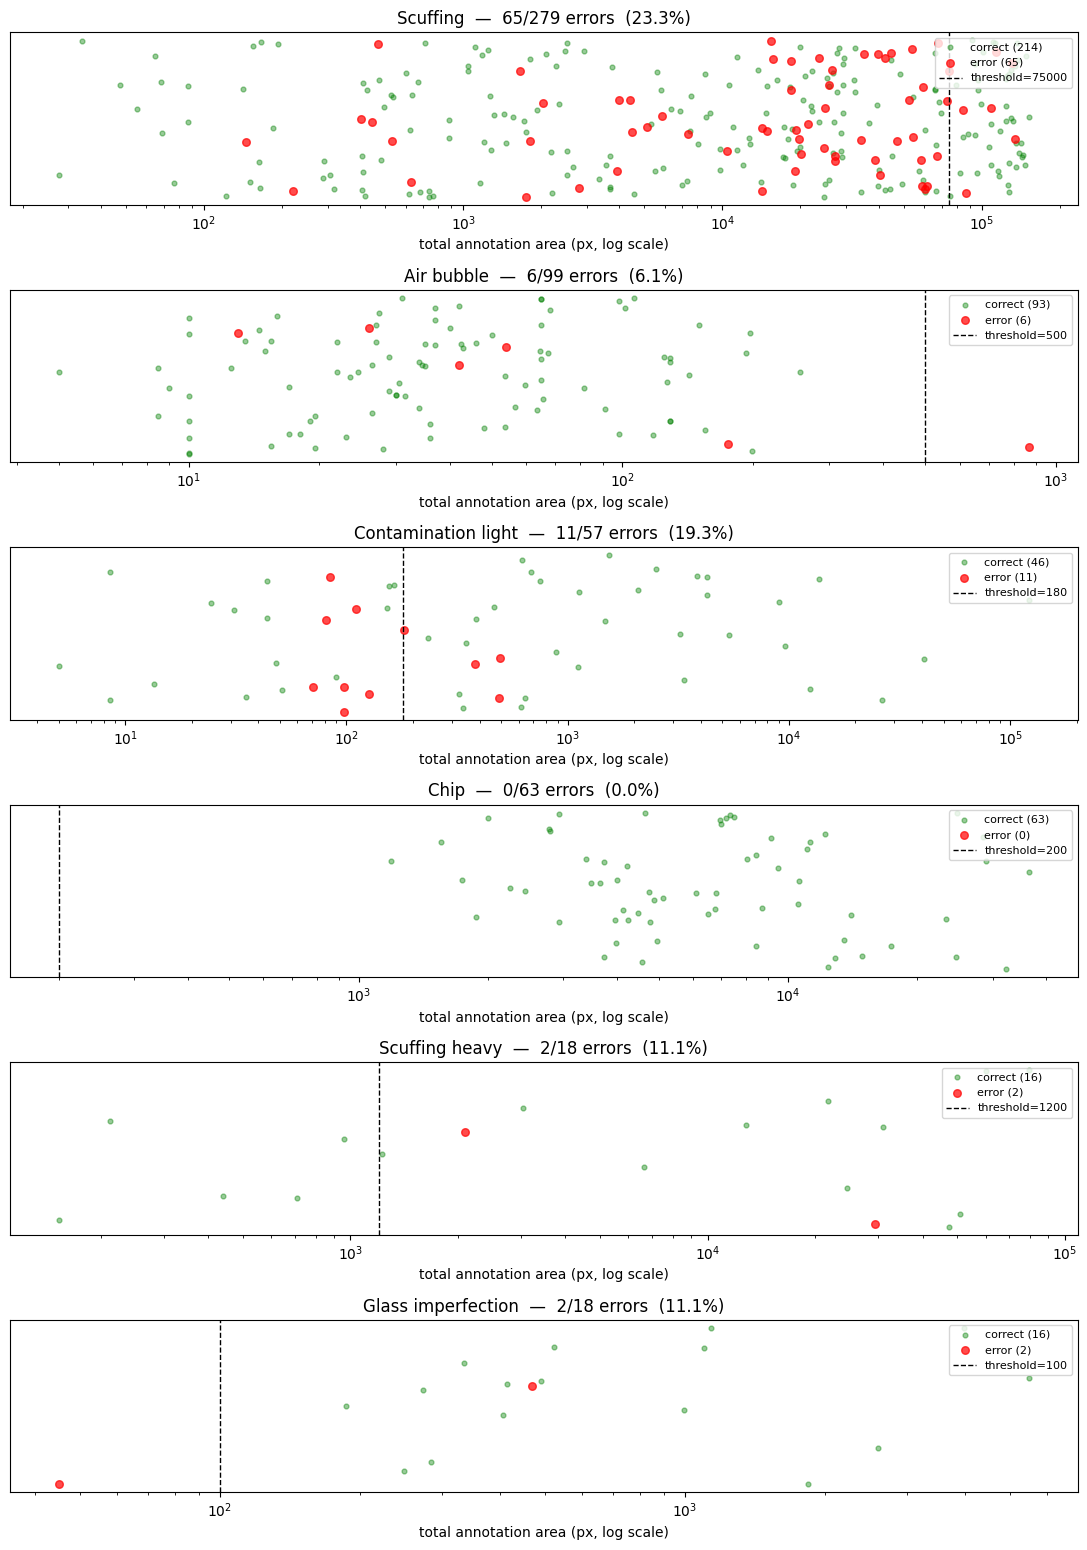

In [4]:
cond_classes = list(CONDITIONAL.keys())
n = len(cond_classes)
fig, axes = plt.subplots(n, 1, figsize=(11, 2.6 * n))
for i, cls in enumerate(cond_classes):
    sub = df[df["class"] == cls].copy()
    if len(sub) == 0:
        axes[i].text(
            0.5, 0.5, f"{cls}: no images in this split", ha="center", va="center"
        )
        axes[i].set_axis_off()
        continue
    thr = CONDITIONAL[cls]
    correct = sub[sub["error"] == 0]
    errs = sub[sub["error"] == 1]
    axes[i].scatter(
        correct["cond_area"] + 1,
        np.random.uniform(-0.1, 0.1, len(correct)),
        c="green",
        s=12,
        alpha=0.4,
        label=f"correct ({len(correct)})",
    )
    axes[i].scatter(
        errs["cond_area"] + 1,
        np.random.uniform(-0.1, 0.1, len(errs)),
        c="red",
        s=30,
        alpha=0.7,
        label=f"error ({len(errs)})",
    )
    axes[i].axvline(
        thr, color="black", linestyle="--", linewidth=1, label=f"threshold={thr}"
    )
    axes[i].set_xscale("log")
    axes[i].set_yticks([])
    axes[i].set_xlabel("total annotation area (px, log scale)")
    axes[i].set_title(
        f"{cls}  —  {len(errs)}/{len(sub)} errors  ({len(errs) / len(sub) * 100:.1f}%)"
    )
    axes[i].legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

In [5]:
# Quantify: what fraction of errors are within +/- 50% of threshold?
print("Are errors clustered near the threshold? (band = +/- 50%)\n")
for cls in cond_classes:
    sub = df[(df["class"] == cls) & (df["error"] == 1)]
    if len(sub) == 0:
        print(f"  {cls:24s} — no errors")
        continue
    thr = CONDITIONAL[cls]
    near = ((sub["cond_area"] >= thr * 0.5) & (sub["cond_area"] <= thr * 1.5)).sum()
    pct = near / len(sub) * 100
    print(
        f"  {cls:24s}: {near}/{len(sub)} errors near threshold ({pct:.0f}%)  thr={thr}"
    )

Are errors clustered near the threshold? (band = +/- 50%)

  Scuffing                : 21/65 errors near threshold (32%)  thr=75000
  Air bubble              : 0/6 errors near threshold (0%)  thr=500
  Contamination light     : 5/11 errors near threshold (45%)  thr=180
  Chip                     — no errors
  Scuffing heavy          : 0/2 errors near threshold (0%)  thr=1200
  Glass imperfection      : 0/2 errors near threshold (0%)  thr=100


## 3. What do the errors look like? Visual inspection

Grids of misclassified images, sorted by confidence. If the model erred *confidently* (prob = 0.99 but label = 0, or vice versa), those are the worst cases — either label noise or genuine model blind spots.

In [6]:
def show_grid(df_sub, title, n_show=12, cols=4):
    if len(df_sub) == 0:
        print(f"{title}: no images")
        return
    df_sub = df_sub.head(n_show)
    rows = (len(df_sub) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(3.2 * cols, 3.2 * rows))
    fig.suptitle(title, fontsize=12, y=1.0)
    axes = np.atleast_2d(axes)
    for i, row in enumerate(df_sub.itertuples()):
        r, c = i // cols, i % cols
        path = CROPS_DIR / row.file_name
        if path.exists():
            img = Image.open(path).convert("L")
            axes[r, c].imshow(img, cmap="gray")
        axes[r, c].set_title(
            f"{row._asdict().get('class', '?')}\n"
            f"true={row.label}  pred={row.predbest}  prob={row.prob:.2f}\n"
            f"area={row.cond_area:.0f}",
            fontsize=8,
        )
        axes[r, c].axis("off")
    for j in range(len(df_sub), rows * cols):
        axes[j // cols, j % cols].axis("off")
    plt.tight_layout()
    plt.show()

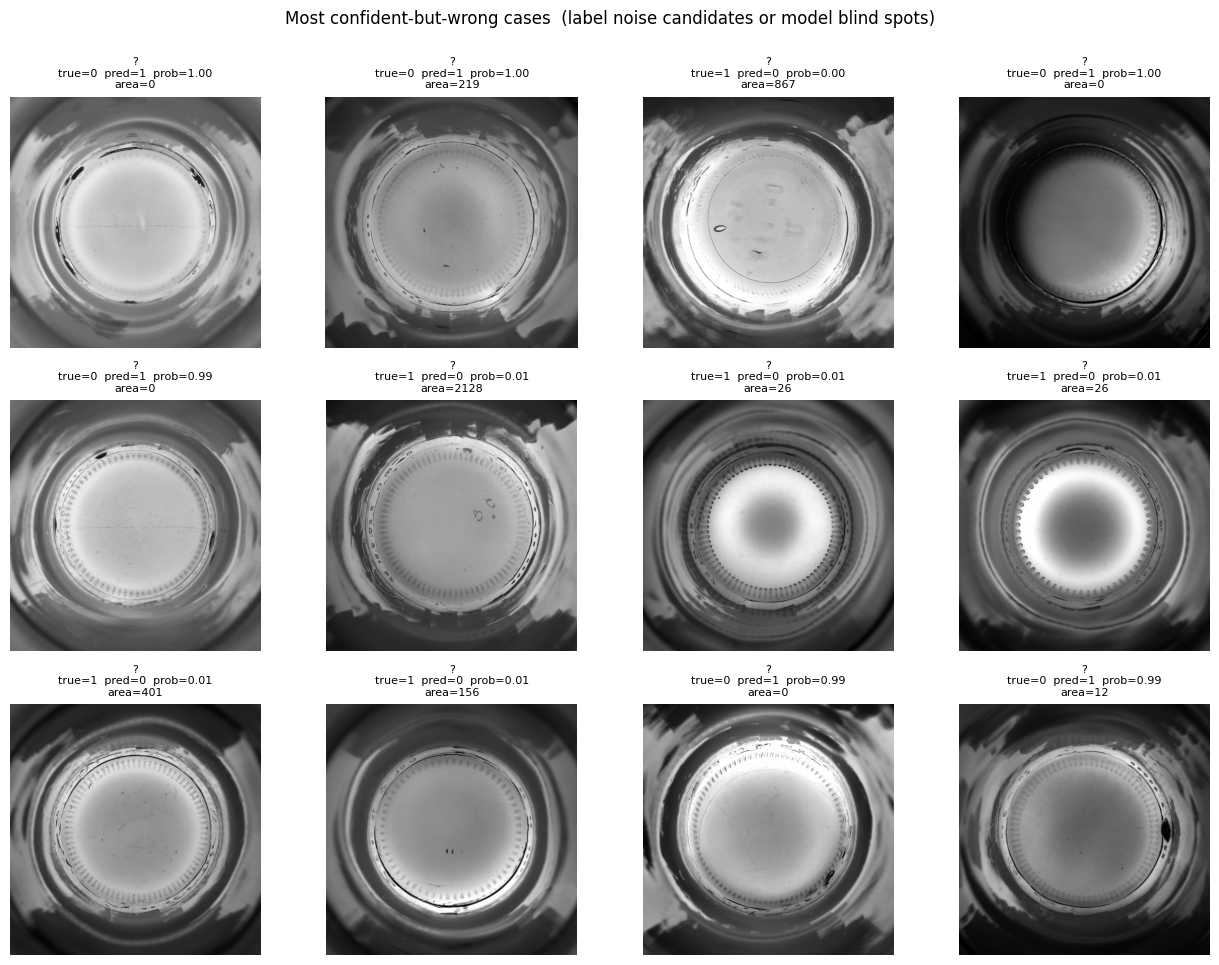


classes involved:
class
Good_no_defect        4
Contamination dark    3
Scuffing              2
Air bubble            2
Mold                  1


In [7]:
# 3a. Most-confident-wrong cases (model said one thing strongly, label was the other)
errors = df[df["error"] == 1].copy()
errors["confidence"] = np.where(
    errors["predbest"] == 1, errors["prob"], 1 - errors["prob"]
)
very_confident_errors = errors.sort_values("confidence", ascending=False).head(12)
show_grid(
    very_confident_errors,
    "Most confident-but-wrong cases  (label noise candidates or model blind spots)",
)
print("\nclasses involved:")
print(very_confident_errors["class"].value_counts().to_string())

Scuffing errors: 65

breakdown:
  area < threshold (75000) and predicted Faulty (FP): 47
  area > threshold (75000) and predicted Good   (FN): 6


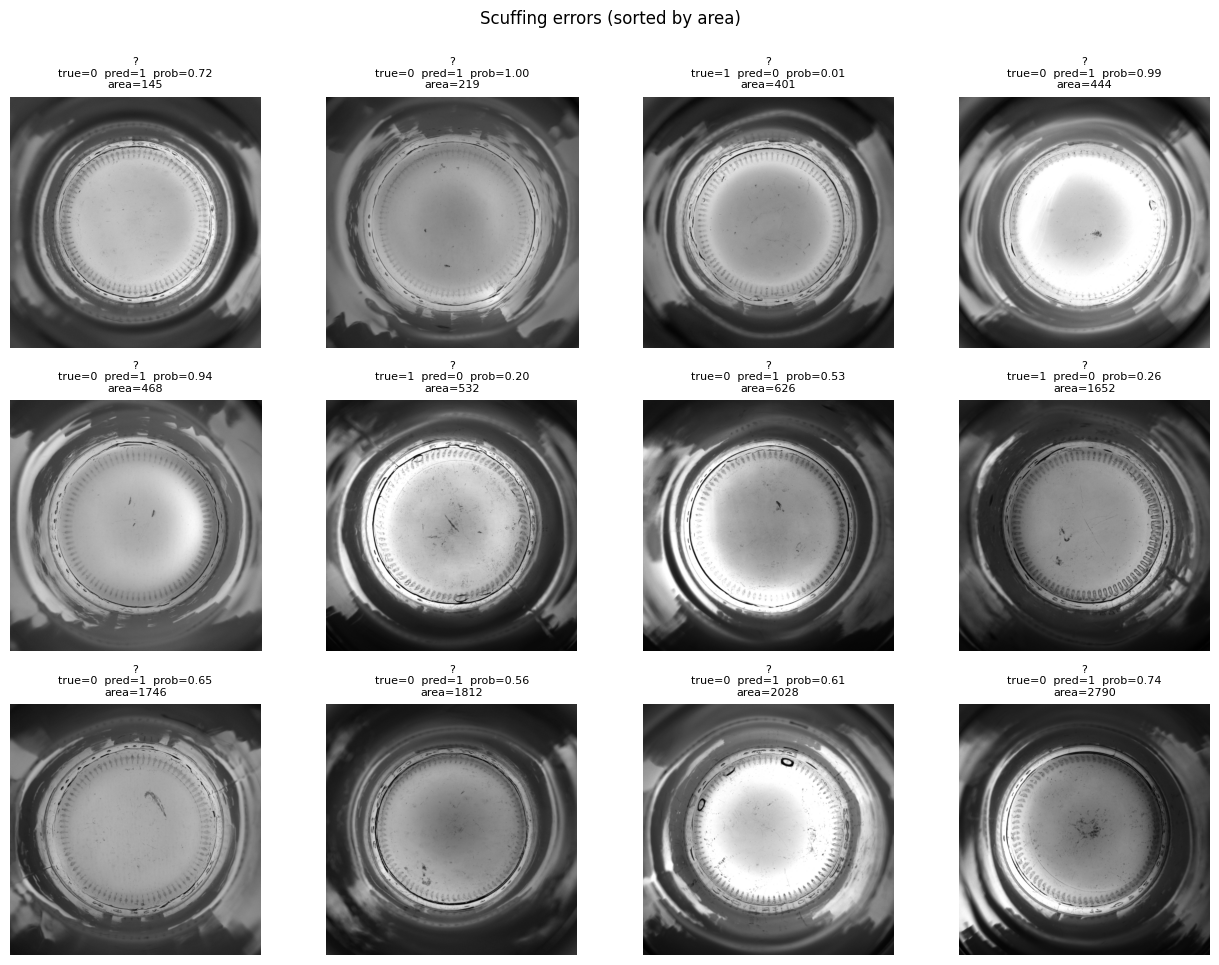

In [8]:
# 3b. Scuffing errors specifically
scuff_errors = df[(df["class"] == "Scuffing") & (df["error"] == 1)].copy()
scuff_errors = scuff_errors.sort_values("cond_area")
print(f"Scuffing errors: {len(scuff_errors)}\n")
print("breakdown:")
print(
    f"  area < threshold (75000) and predicted Faulty (FP): "
    f"{((scuff_errors['cond_area'] < 75000) & (scuff_errors['predbest'] == 1)).sum()}"
)
print(
    f"  area > threshold (75000) and predicted Good   (FN): "
    f"{((scuff_errors['cond_area'] >= 75000) & (scuff_errors['predbest'] == 0)).sum()}"
)
show_grid(scuff_errors.head(12), "Scuffing errors (sorted by area)")

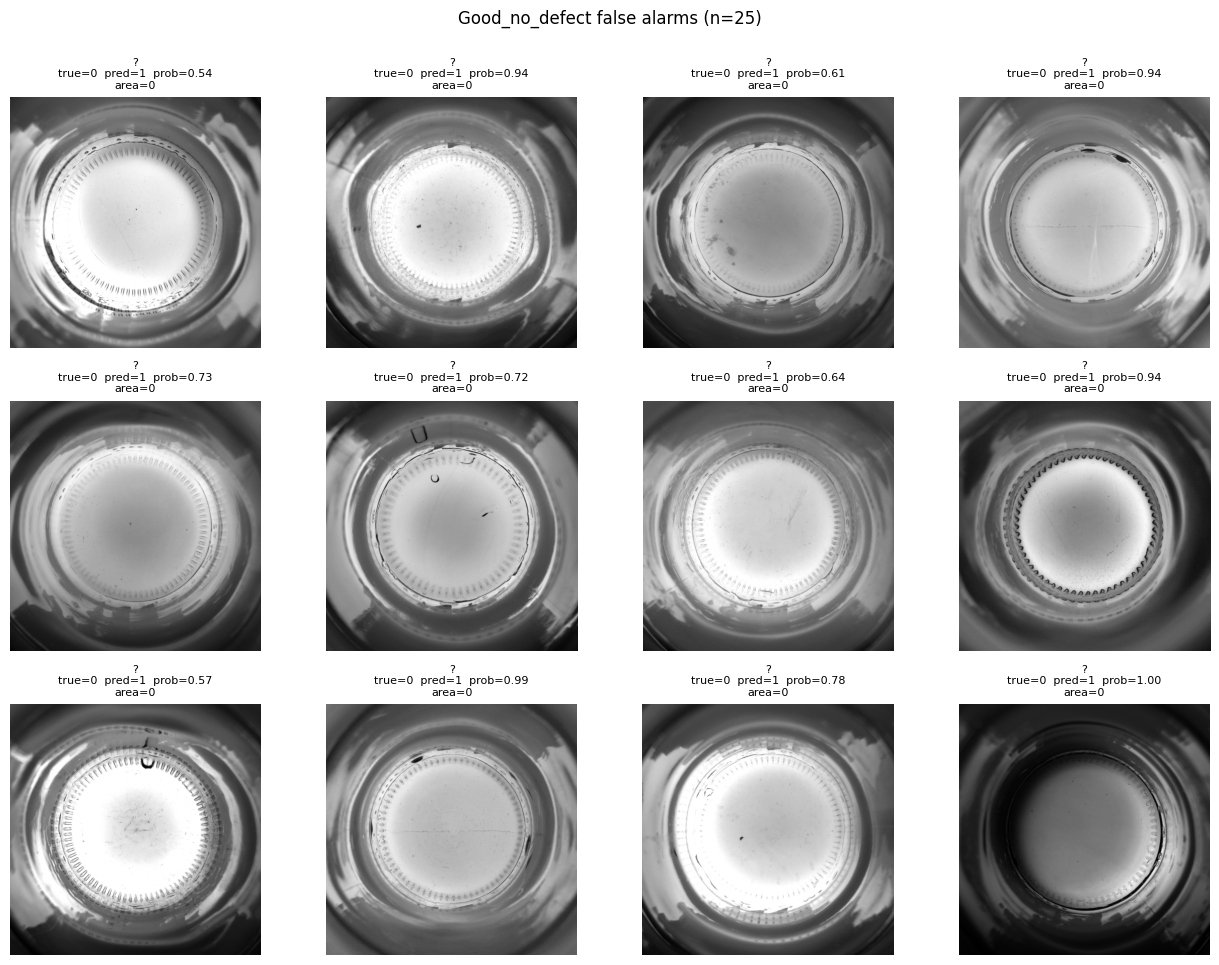

In [9]:
# 3c. Good_no_defect false alarms — what makes the model think these are Faulty?
fp_good = df[(df["class"] == "Good_no_defect") & (df["error"] == 1)]
show_grid(fp_good.head(12), f"Good_no_defect false alarms (n={len(fp_good)})")

## 4. Confidence distribution of errors

If errors are mostly low-confidence (prob near 0.5), the model knows it's uncertain — TTA / threshold tuning helps these.
If errors are high-confidence, the model is *wrong* and certain — these are the hard cases that need representation changes (segmentation, more data, different architecture).

/tmp/ipykernel_444022/2579954708.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  errors['confidence'] = np.where(errors['predbest']==1, errors['prob'], 1-errors['prob'])


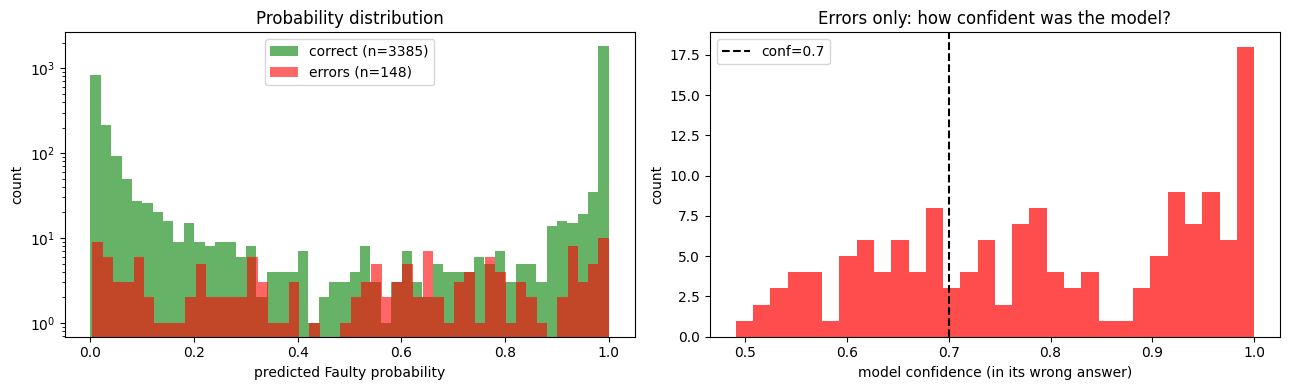


Errors with confidence <= 0.7  (uncertain): 48  (32%)
Errors with confidence >  0.7  (confident):  100 (68%)


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
correct = df[df["error"] == 0]
errors = df[df["error"] == 1]
axes[0].hist(
    correct["prob"],
    bins=50,
    alpha=0.6,
    label=f"correct (n={len(correct)})",
    color="green",
)
axes[0].hist(
    errors["prob"], bins=50, alpha=0.6, label=f"errors (n={len(errors)})", color="red"
)
axes[0].set_xlabel("predicted Faulty probability")
axes[0].set_ylabel("count")
axes[0].set_title("Probability distribution")
axes[0].set_yscale("log")
axes[0].legend()
errors["confidence"] = np.where(
    errors["predbest"] == 1, errors["prob"], 1 - errors["prob"]
)
axes[1].hist(errors["confidence"], bins=30, color="red", alpha=0.7)
axes[1].axvline(0.7, color="black", linestyle="--", label="conf=0.7")
axes[1].set_xlabel("model confidence (in its wrong answer)")
axes[1].set_ylabel("count")
axes[1].set_title("Errors only: how confident was the model?")
axes[1].legend()
plt.tight_layout()
plt.show()

low_conf = (errors["confidence"] <= 0.7).sum()
high_conf = (errors["confidence"] > 0.7).sum()
print(
    f"\nErrors with confidence <= 0.7  (uncertain): {low_conf}  ({low_conf / len(errors) * 100:.0f}%)"
)
print(
    f"Errors with confidence >  0.7  (confident):  {high_conf} ({high_conf / len(errors) * 100:.0f}%)"
)

## 5. Per-class error decomposition with severity

In [11]:
rows = []
for cls, grp in df.groupby("class"):
    err = grp[grp["error"] == 1]
    rows.append(
        {
            "class": cls,
            "n": len(grp),
            "n_errors": len(err),
            "error_rate": len(err) / len(grp),
            "avg_conf_when_wrong": (
                np.where(err["predbest"] == 1, err["prob"], 1 - err["prob"]).mean()
                if len(err)
                else np.nan
            ),
            "is_conditional": cls in CONDITIONAL,
        }
    )
summary = pd.DataFrame(rows).sort_values("n_errors", ascending=False)
print(summary.to_string(index=False))

total_err = summary["n_errors"].sum()
cond_err = summary[summary["is_conditional"]]["n_errors"].sum()
print(f"\nTotal errors: {total_err}")
print(
    f"Conditional-class errors: {cond_err}  ({cond_err / total_err * 100:.1f}% of all errors)"
)

                           class    n  n_errors  error_rate  avg_conf_when_wrong  is_conditional
                        Scuffing  279        65    0.232975             0.767653            True
              Contamination dark  397        30    0.075567             0.842450           False
                  Good_no_defect 1161        25    0.021533             0.777374           False
             Contamination light   57        11    0.192982             0.729428            True
                            Mold  186         7    0.037634             0.818869           False
                      Air bubble   99         6    0.060606             0.925522            True
              Glass imperfection   18         2    0.111111             0.960036            True
                  Scuffing heavy   18         2    0.111111             0.741306            True
                         Circlip    4         0    0.000000                  NaN           False
                   Break / Cra

## 6. The verdict

Read the output of the cells above and decide:

**Path A — the gain is in classification tuning.** True if:
- Errors are mostly low-confidence (>50% have confidence ≤ 0.7)
- Errors near conditional thresholds (clustered within ±50% of threshold)
- Significant fraction of errors come from non-conditional classes

**Path B — segmentation will give the most gain.** True if:
- Conditional-class errors > 60% of total
- Many high-confidence errors on conditional borderline cases (model is *confidently wrong*)
- Errors *not* clustered near threshold (spread broadly), meaning model isn't measuring area

**Path C — there's a third issue we didn't predict.** True if:
- Most-confident errors are weird visual cases (wrong ROI crop, label noise, lighting outliers)
- This means we should fix the data / inference pipeline first